# Tema 12 — Datos geoespaciales
**Curso:** ME101 Programación Estadística y Visualización de Datos  
**Estudiante:** José Ángel  
**Semana 12** — Coordenadas, proyecciones y formatos (sin geopandas)

## Tarea 1 — Coordenadas y mapa básico
Lugares reales que uso en mi día a día: mi casa en Anta, la dirección de la Tóxica, la universidad (UNSAAC) y el terminal desde donde salen los buses hacia Anta en Cusco. Coordenadas en WGS84 (EPSG:4326), tomadas de Google Maps.

In [1]:
lugares = {
    "Mi casa (Anta)":            (-13.466745109914163, -72.14285007331435),
    "UNSAAC":                    (-13.521836103877215, -71.95832523250834),
    "Tóxica":                    (-13.465918778174718, -72.14626032869427),
    "Terminal de buses a Anta":  (-13.527465340353357, -71.95815050215658),
}

for nombre, (lat, lon) in lugares.items():
    print(f"{nombre}: lat={lat}, lon={lon}")

Mi casa (Anta): lat=-13.466745109914163, lon=-72.14285007331435
UNSAAC: lat=-13.521836103877215, lon=-71.95832523250834
Tóxica: lat=-13.465918778174718, lon=-72.14626032869427
Terminal de buses a Anta: lat=-13.527465340353357, lon=-71.95815050215658


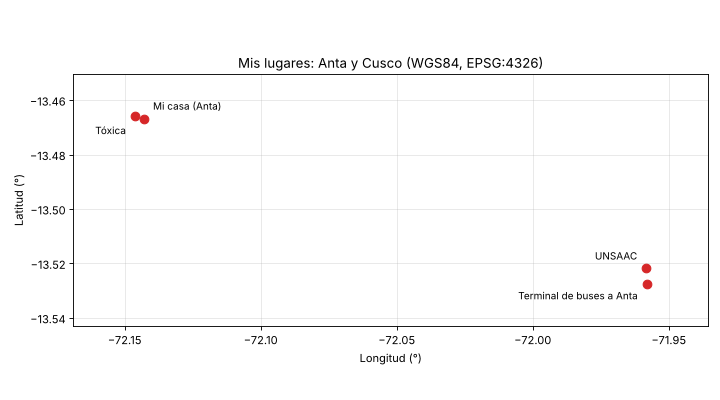

In [2]:
import matplotlib.pyplot as plt

nombres = list(lugares.keys())
lats = [lat for lat, lon in lugares.values()]
lons = [lon for lat, lon in lugares.values()]

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(lons, lats, s=60, color="tab:red", zorder=3)
desplaz = {"Mi casa (Anta)": (8, 8), "Tóxica": (-8, -16),
           "UNSAAC": (-8, 8), "Terminal de buses a Anta": (-8, -14)}
for nombre, lat, lon in zip(nombres, lats, lons):
    dx, dy = desplaz[nombre]
    ax.annotate(nombre, (lon, lat), xytext=(dx, dy), textcoords="offset points",
                ha="right" if dx < 0 else "left", fontsize=9)
ax.set_xlabel("Longitud (°)")
ax.set_ylabel("Latitud (°)")
ax.set_title("Mis lugares: Anta y Cusco (WGS84, EPSG:4326)")
ax.set_aspect("equal")
ax.margins(x=0.12, y=0.25)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("mapa_basico.png", dpi=150)
plt.show()

## Tarea 2 — Distancia con la fórmula de Haversine

In [3]:
import math

def distancia_haversine(lat1, lon1, lat2, lon2):
    """Distancia en km sobre una esfera de radio 6371 km."""
    R = 6371.0
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)
    a = math.sin(dphi / 2) ** 2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2) ** 2
    c = 2 * math.asin(math.sqrt(a))
    return R * c

# prueba rápida: 1° de latitud ≈ 111.19 km
print(round(distancia_haversine(0, 0, 1, 0), 2), "km")

111.19 km


In [4]:
primer_nombre = nombres[0]
lat0, lon0 = lugares[primer_nombre]
print(f"Distancias desde {primer_nombre}:")
for nombre, (lat, lon) in list(lugares.items())[1:]:
    d = distancia_haversine(lat0, lon0, lat, lon)
    print(f"  -> {nombre}: {d:.3f} km")

Distancias desde Mi casa (Anta):
  -> UNSAAC: 20.871 km
  -> Tóxica: 0.380 km
  -> Terminal de buses a Anta: 21.081 km


In [5]:
from itertools import combinations

pares = []
for (n1, (la1, lo1)), (n2, (la2, lo2)) in combinations(lugares.items(), 2):
    pares.append((n1, n2, distancia_haversine(la1, lo1, la2, lo2)))

for n1, n2, d in sorted(pares, key=lambda p: p[2]):
    print(f"{n1:26s} - {n2:26s} {d:7.3f} km")

cercano = min(pares, key=lambda p: p[2])
lejano = max(pares, key=lambda p: p[2])
print(f"\nPar MÁS cercano: {cercano[0]} y {cercano[1]} -> {cercano[2]:.3f} km")
print(f"Par MÁS lejano:  {lejano[0]} y {lejano[1]} -> {lejano[2]:.3f} km")

Mi casa (Anta)             - Tóxica                       0.380 km
UNSAAC                     - Terminal de buses a Anta     0.626 km
Mi casa (Anta)             - UNSAAC                      20.871 km
Mi casa (Anta)             - Terminal de buses a Anta    21.081 km
UNSAAC                     - Tóxica                      21.251 km
Tóxica                     - Terminal de buses a Anta    21.460 km

Par MÁS cercano: Mi casa (Anta) y Tóxica -> 0.380 km
Par MÁS lejano:  Tóxica y Terminal de buses a Anta -> 21.460 km


## Tarea 3 — Escribir y leer GeoJSON
Ojo: en GeoJSON el orden es **[longitud, latitud]**. Incluyo también el reto opcional: una `LineString` que simula la ruta de mi casa a la UNSAAC.

In [6]:
import json

features = []
for nombre, (lat, lon) in lugares.items():
    features.append({
        "type": "Feature",
        "geometry": {"type": "Point", "coordinates": [lon, lat]},   # [lon, lat]
        "properties": {"nombre": nombre},
    })

# Reto opcional: ruta simple Mi casa -> UNSAAC
lat_a, lon_a = lugares["Mi casa (Anta)"]
lat_b, lon_b = lugares["UNSAAC"]
features.append({
    "type": "Feature",
    "geometry": {"type": "LineString", "coordinates": [[lon_a, lat_a], [lon_b, lat_b]]},
    "properties": {"nombre": "Ruta Mi casa -> UNSAAC",
                   "distancia_km": round(distancia_haversine(lat_a, lon_a, lat_b, lon_b), 3)},
})

geojson_mio = {"type": "FeatureCollection", "features": features}

with open("mis_lugares.geojson", "w", encoding="utf-8") as f:
    json.dump(geojson_mio, f, ensure_ascii=False, indent=2)
print("Guardado mis_lugares.geojson con", len(features), "features")

Guardado mis_lugares.geojson con 5 features


In [7]:
with open("mis_lugares.geojson", encoding="utf-8") as f:
    datos = json.load(f)

puntos = [ft for ft in datos["features"] if ft["geometry"]["type"] == "Point"]
print("Total de features:", len(datos["features"]))
print("Features de tipo Point:", len(puntos), "| lugares en el diccionario:", len(lugares))

primero = puntos[0]
lon_leida, lat_leida = primero["geometry"]["coordinates"]
print("Primer lugar:", primero["properties"]["nombre"], "->", primero["geometry"]["coordinates"])

assert len(puntos) == len(lugares)
assert (lat_leida, lon_leida) == lugares[primer_nombre]
print("Verificación OK: el número de puntos y las coordenadas coinciden.")

Total de features: 5
Features de tipo Point: 4 | lugares en el diccionario: 4
Primer lugar: Mi casa (Anta) -> [-72.14285007331435, -13.466745109914163]
Verificación OK: el número de puntos y las coordenadas coinciden.
